## 1. Import libraries

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

print("TensorFlow version:", tf.__version__)

I0000 00:00:1793651446.665328    5174 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793651447.090296    5174 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793651448.419029    5174 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow version: 2.21.0


## Common helper: display training graphs

The same graph format is used for every dataset.

In [2]:
def plot_history(history):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    plt.show()

## 1A. FNN – MNIST handwritten digit classification

- Image size: 28 × 28 grayscale
- Output classes: 10
- Optimizer: SGD
- Epochs: 11

### Load training and testing data

In [3]:
df_train = pd.read_csv("dataset/fnn_cnn/hand/mnist_train.csv")
df_test = pd.read_csv("dataset/fnn_cnn/hand/mnist_test.csv")

In [4]:
x_train = df_train.drop('label', axis=1).values
y_train = df_train['label'].values

x_test = df_test.drop('label', axis=1).values
y_test = df_test['label'].values

In [5]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


### Preprocess data

In [6]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

### Define the network architecture

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784, )),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

E0000 00:00:1793651464.364977    5174 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

In [10]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9316 - loss: 0.2379 - val_accuracy: 0.9457 - val_loss: 0.1896
Epoch 2/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9329 - loss: 0.2309 - val_accuracy: 0.9484 - val_loss: 0.1847
Epoch 3/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9367 - loss: 0.2226 - val_accuracy: 0.9492 - val_loss: 0.1798
Epoch 4/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9375 - loss: 0.2149 - val_accuracy: 0.9513 - val_loss: 0.1751
Epoch 5/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9387 - loss: 0.2094 - val_accuracy: 0.9531 - val_loss: 0.1704
Epoch 6/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9414 - loss: 0.2033 - val_accuracy: 0.9532 - val_loss: 0.1663
Epoch 7/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9433 - loss: 0.1966 - val_accuracy: 0.9546 - val_loss: 0.1619
Epoch 8/11
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9450 - loss: 0.1909 - val_accuracy: 0.

### Evaluate the model

In [11]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 710us/step - accuracy: 0.9540 - loss: 0.1531
Test Loss: 0.1530534327030182
Test Accuracy: 0.9539999961853027


### Plot training loss and accuracy

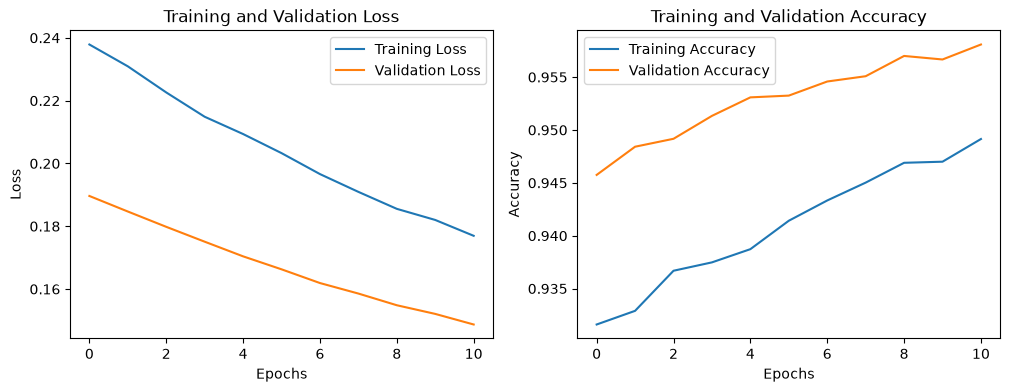

In [12]:
plot_history(history)

## 1B. FNN – Fashion MNIST classification

- Image size: 28 × 28 grayscale
- Output classes: 10
- Optimizer: SGD
- Epochs: 10

**Correction to the practical sheet:** This section uses Fashion MNIST, not CIFAR-10.

### Load training and testing data

In [14]:
df_train = pd.read_csv("dataset/fnn_cnn/fashion/fashion-mnist_train.csv")
df_test = pd.read_csv("dataset/fnn_cnn/fashion/fashion-mnist_test.csv")

In [15]:
x_train = df_train.drop('label', axis=1).values
y_train = df_train['label'].values

x_test = df_test.drop('label', axis=1).values
y_test = df_test['label'].values

In [16]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


### Preprocess data

In [18]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

### Define the network architecture

In [19]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784, )),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Train the model

In [20]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/10


W0000 00:00:1793562016.234479  195320 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.


469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6554 - loss: 1.0878 - val_accuracy: 0.7548 - val_loss: 0.7216
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7622 - loss: 0.6974 - val_accuracy: 0.7977 - val_loss: 0.6052
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7913 - loss: 0.6098 - val_accuracy: 0.8193 - val_loss: 0.5458
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8074 - loss: 0.5625 - val_accuracy: 0.8241 - val_loss: 0.5143
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8173 - loss: 0.5307 - val_accuracy: 0.8334 - val_loss: 0.4868
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8254 - loss: 0.5089 - val_accuracy: 0.8371 - val_loss: 0.4718
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8311 - loss: 0.4900 - val_accuracy: 0.8397 - val_loss: 0.4597
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8352 - loss: 0.4753 - val_accuracy: 0.8486 - val_

### Evaluate the model

In [21]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8524 - loss: 0.4298
Test Loss: 0.4297633767127991
Test Accuracy: 0.852400004863739


### Plot training loss and accuracy

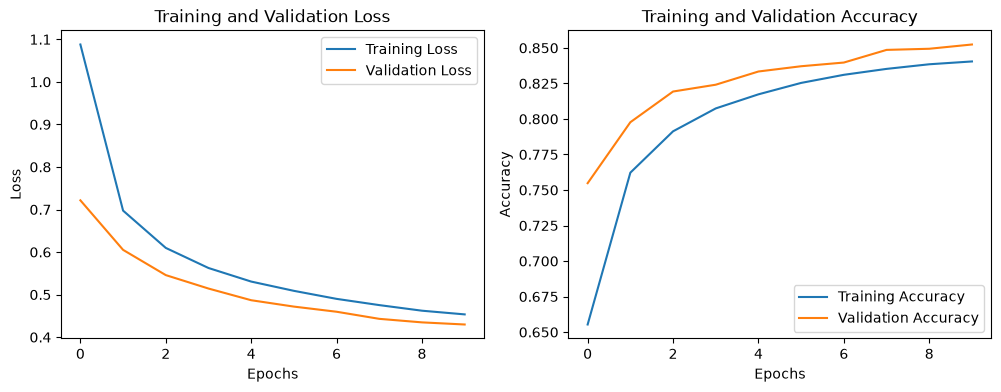

In [22]:
plot_history(history)

## 1C. FNN – CIFAR-10 image classification

- Image size: 32 × 32 RGB
- Output classes: 10
- Optimizer: Adam
- Epochs: 10

CIFAR-10 images have three colour channels. A plain FNN can classify them, but usually performs worse than a CNN.

### Load training and testing data

In [23]:
df = pd.read_csv('dataset/fnn_cnn/CIFAR10/cifar-10.csv')

In [29]:
x = df.drop('label', axis=1).values
y = df['label'].values

In [30]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [31]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (40000, 3072)
Testing data: (10000, 3072)


### Preprocess data

In [32]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

### Define the network architecture

In [35]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(3072, )),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

### Train the model

In [36]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/10


W0000 00:00:1793562511.877451  195320 cpu_allocator_impl.cc:82] Allocation of 491520000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.2641 - loss: 2.0084 - val_accuracy: 0.3411 - val_loss: 1.8071
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.3330 - loss: 1.8353 - val_accuracy: 0.3623 - val_loss: 1.7721
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.3623 - loss: 1.7726 - val_accuracy: 0.3946 - val_loss: 1.6821
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.3708 - loss: 1.7373 - val_accuracy: 0.4005 - val_loss: 1.6627
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.3837 - loss: 1.7037 - val_accuracy: 0.4125 - val_loss: 1.6383
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.3931 - loss: 1.6758 - val_accuracy: 0.4273 - val_loss: 1.6050
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.4027 - loss: 1.6548 - val_accuracy: 0.4184 - val_loss: 1.6148
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.4115 - loss: 1.6281 - val_accuracy: 0.431

### Evaluate the model

In [37]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.4490 - loss: 1.5472
Test Loss: 1.5472372770309448
Test Accuracy: 0.4490000009536743


### Plot training loss and accuracy

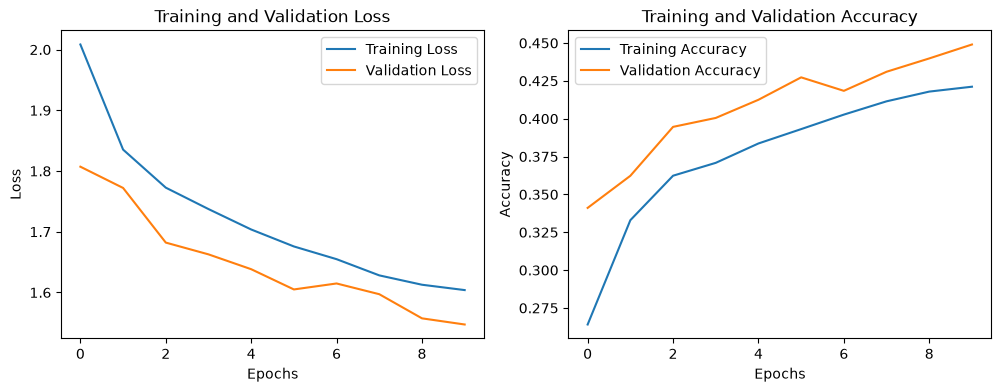

In [38]:
plot_history(history)

## 1E. FNN – Sign Language MNIST classification

- Image size: 28 × 28 grayscale (784 pixel values)
- Output classes: 24
- Optimizer: Adam
- Epochs: 10

**Dataset files required:** `sign_mnist_train.csv` and `sign_mnist_test.csv`. Place both files in the same folder as this notebook. Each CSV must contain a `label` column followed by 784 pixel columns.

### Load training and testing data

In [52]:
train_data = pd.read_csv('dataset/fnn_cnn/sign/sign_mnist_train.csv')
test_data = pd.read_csv('dataset/fnn_cnn/sign/sign_mnist_test.csv')

x_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (27455, 784)
Testing data: (7172, 784)


### Preprocess data

In [53]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

### Define the network architecture

In [69]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(24, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_42 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_45 (Dense)                │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 569,240 (2.17 MB)

 Trainable params: 569,240 (2.17 MB)

 Non-trainable params: 0 (0.00 B)

### Train the model

In [70]:
history = model.fit(
    x_train, y_train,
    epochs=11,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.2611 - loss: 2.3605 - val_accuracy: 0.4766 - val_loss: 1.6310
Epoch 2/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5228 - loss: 1.4116 - val_accuracy: 0.5740 - val_loss: 1.2226
Epoch 3/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6362 - loss: 1.0549 - val_accuracy: 0.6429 - val_loss: 1.0305
Epoch 4/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7206 - loss: 0.8103 - val_accuracy: 0.6835 - val_loss: 0.9603
Epoch 5/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7622 - loss: 0.6783 - val_accuracy: 0.7497 - val_loss: 0.7770
Epoch 6/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8020 - loss: 0.5637 - val_accuracy: 0.7567 - val_loss: 0.7696
Epoch 7/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8232 - loss: 0.4995 - val_accuracy: 0.7616 - val_loss: 0.7824
Epoch 8/20
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8372 - loss: 0.4555 - val_accuracy: 0.

### Evaluate the model

In [71]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8173 - loss: 0.6154
Test Loss: 0.6153544783592224
Test Accuracy: 0.8173452019691467


### Plot training loss and accuracy

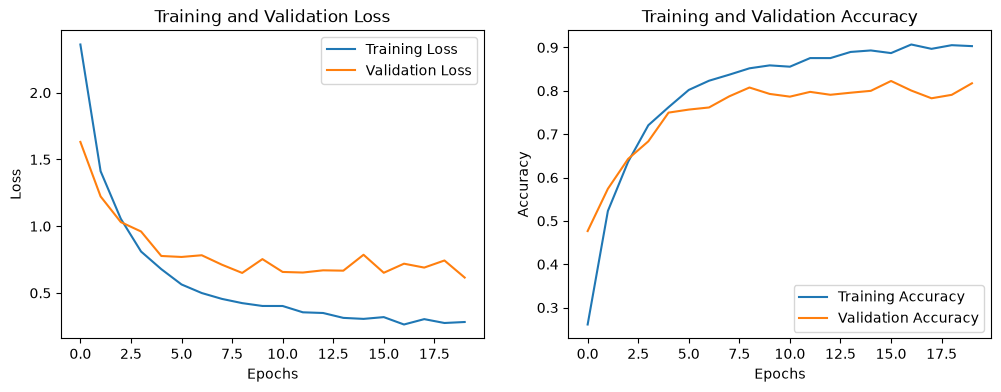

In [72]:
plot_history(history)